In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
np.random.seed(42)

categories = [
    "Food", "Transport", "Shopping", "Bills",
    "Entertainment", "Healthcare", "Education"
]

payment_methods = ["Cash", "UPI", "Debit Card", "Credit Card"]

dates = pd.date_range("2026-01-01", "2026-06-30")

df_sample = pd.DataFrame({
    "Date": np.random.choice(dates, 100),
    "Category": np.random.choice(categories, 100),
    "Amount": np.random.randint(50, 3001, 100),
    "Payment_Method": np.random.choice(payment_methods, 100),
    "Description": np.random.choice(
        ["Lunch", "Travel", "Groceries", "Shopping",
         "Electricity", "Movie", "Medicine", "Course"],
        100
    )
})

# Introduce a few data-quality problems for practice
df_sample.loc[3, "Category"] = np.nan
df_sample.loc[8, "Amount"] = np.nan
df_sample.loc[12, "Payment_Method"] = np.nan
df_sample.loc[15, "Date"] = "invalid-date"

# Add a duplicate row
df_sample = pd.concat(
    [df_sample, df_sample.iloc[[0]]],
    ignore_index=True
)

df_sample.to_csv("personal_expenses.csv", index=False)

print("CSV file created!")
df_sample.head()

CSV file created!


/tmp/ipykernel_716/1377826562.py:28: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'invalid-date' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.
  df_sample.loc[15, "Date"] = "invalid-date"


,Date,Category,Amount,Payment_Method,Description
0,2026-04-13 00:00:00,Shopping,698.0,UPI,Course
1,2026-06-29 00:00:00,Food,367.0,Credit Card,Groceries
2,2026-04-03 00:00:00,Shopping,1307.0,Credit Card,Course
3,2026-01-15 00:00:00,NaN,733.0,UPI,Travel
4,2026-04-17 00:00:00,Transport,713.0,Debit Card,Lunch


In [ ]:
df = pd.read_csv("personal_expenses.csv")

df.head(10)

,Date,Category,Amount,Payment_Method,Description
0,2026-04-13 00:00:00,Shopping,698.0,UPI,Course
1,2026-06-29 00:00:00,Food,367.0,Credit Card,Groceries
2,2026-04-03 00:00:00,Shopping,1307.0,Credit Card,Course
3,2026-01-15 00:00:00,NaN,733.0,UPI,Travel
4,2026-04-17 00:00:00,Transport,713.0,Debit Card,Lunch
5,2026-03-13 00:00:00,Education,2048.0,Credit Card,Travel
6,2026-01-21 00:00:00,Transport,1681.0,UPI,Medicine
7,2026-04-13 00:00:00,Food,1545.0,Cash,Movie
8,2026-05-02 00:00:00,Bills,NaN,Debit Card,Travel
9,2026-03-16 00:00:00,Education,1903.0,Cash,Groceries


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.columns

Rows: 101
Columns: 5


Index(['Date', 'Category', 'Amount', 'Payment_Method', 'Description'], dtype='object')

In [ ]:
# First five rows
display(df.head())


,Date,Category,Amount,Payment_Method,Description
0,2026-04-13 00:00:00,Shopping,698.0,UPI,Course
1,2026-06-29 00:00:00,Food,367.0,Credit Card,Groceries
2,2026-04-03 00:00:00,Shopping,1307.0,Credit Card,Course
3,2026-01-15 00:00:00,NaN,733.0,UPI,Travel
4,2026-04-17 00:00:00,Transport,713.0,Debit Card,Lunch


In [ ]:
# Last five rows
display(df.tail())


,Date,Category,Amount,Payment_Method,Description
96,2026-05-19 00:00:00,Shopping,677.0,Cash,Shopping
97,2026-03-22 00:00:00,Education,636.0,Credit Card,Movie
98,2026-05-16 00:00:00,Healthcare,1698.0,Debit Card,Medicine
99,2026-06-12 00:00:00,Shopping,1493.0,Cash,Groceries
100,2026-04-13 00:00:00,Shopping,698.0,UPI,Course


In [ ]:
# Number of rows and columns
print("Shape:", df.shape)

Shape: (101, 5)


In [ ]:
# Column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            101 non-null    object 
 1   Category        100 non-null    object 
 2   Amount          100 non-null    float64
 3   Payment_Method  100 non-null    object 
 4   Description     101 non-null    object 
dtypes: float64(1), object(4)
memory usage: 4.1+ KB


In [ ]:
# Statistical summary
display(df.describe(include="all"))

,Date,Category,Amount,Payment_Method,Description
count,101,100,100.000000,100,101
unique,76,7,NaN,4,8
top,2026-01-15 00:00:00,Education,NaN,Credit Card,Travel
freq,4,19,NaN,29,18
mean,NaN,NaN,1565.990000,NaN,NaN
std,NaN,NaN,803.124561,NaN,NaN
min,NaN,NaN,51.000000,NaN,NaN
25%,NaN,NaN,744.250000,NaN,NaN
50%,NaN,NaN,1692.000000,NaN,NaN
75%,NaN,NaN,2217.750000,NaN,NaN


In [ ]:
# Missing values in each column
print(df.isnull().sum())

Date              0
Category          1
Amount            1
Payment_Method    1
Description       0
dtype: int64


In [ ]:
# Number of duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1


In [ ]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print(df["Date"].dtype)
print("Invalid dates:", df["Date"].isna().sum())

datetime64[ns]
Invalid dates: 1


In [ ]:
df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")

print(df["Amount"].dtype)

float64


In [ ]:
print("Before removing duplicates:", len(df))

df = df.drop_duplicates()

print("After removing duplicates:", len(df))

Before removing duplicates: 101
After removing duplicates: 100


In [ ]:
df = df.dropna(subset=["Date", "Amount"]).copy()

df["Category"] = df["Category"].fillna("Unknown")
df["Payment_Method"] = df["Payment_Method"].fillna("Unknown")
df["Description"] = df["Description"].fillna("Not specified")

print(df.isnull().sum())
print("Cleaned rows:", len(df))

Date              0
Category          0
Amount            0
Payment_Method    0
Description       0
dtype: int64
Cleaned rows: 98


In [ ]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%B")
df["Year_Month"] = df["Date"].dt.to_period("M").astype(str)
df["Day_Name"] = df["Date"].dt.day_name()
df["Day"] = df["Date"].dt.date

df.head()

,Date,Category,Amount,Payment_Method,Description,Year,Month,Month_Name,Year_Month,Day_Name,Day
0,2026-04-13,Shopping,698.0,UPI,Course,2026,4,April,2026-04,Monday,2026-04-13
1,2026-06-29,Food,367.0,Credit Card,Groceries,2026,6,June,2026-06,Monday,2026-06-29
2,2026-04-03,Shopping,1307.0,Credit Card,Course,2026,4,April,2026-04,Friday,2026-04-03
3,2026-01-15,Unknown,733.0,UPI,Travel,2026,1,January,2026-01,Thursday,2026-01-15
4,2026-04-17,Transport,713.0,Debit Card,Lunch,2026,4,April,2026-04,Friday,2026-04-17


In [ ]:
# Basic expense analysis

In [ ]:
total_spending = df["Amount"].sum()

print(f"Total spending: ₹{total_spending:,.2f}")

Total spending: ₹155,153.00


In [ ]:
print(f"Average expense: ₹{df['Amount'].mean():,.2f}")
print(f"Smallest expense: ₹{df['Amount'].min():,.2f}")
print(f"Largest expense: ₹{df['Amount'].max():,.2f}")
print("Number of expenses:", len(df))

Average expense: ₹1,583.19
Smallest expense: ₹51.00
Largest expense: ₹2,994.00
Number of expenses: 98


In [ ]:
category_counts = df["Category"].value_counts()

display(category_counts)

,count
Category,
Education,18
Shopping,16
Food,15
Bills,14
Healthcare,13
Entertainment,12
Transport,9
Unknown,1


In [ ]:
category_spending = (
    df.groupby("Category")["Amount"]
      .sum()
      .sort_values(ascending=False)
)

display(category_spending)

,Amount
Category,
Bills,26468.0
Education,24912.0
Food,23422.0
Entertainment,22876.0
Shopping,21961.0
Healthcare,21299.0
Transport,13482.0
Unknown,733.0


In [ ]:
category_report = (
    df.groupby("Category")
      .agg(
          Total_Spending=("Amount", "sum"),
          Average_Expense=("Amount", "mean"),
          Transaction_Count=("Amount", "count")
      )
      .sort_values("Total_Spending", ascending=False)
)

display(category_report.round(2))

,Total_Spending,Average_Expense,Transaction_Count
Category,,,
Bills,26468.0,1890.57,14
Education,24912.0,1384.00,18
Food,23422.0,1561.47,15
Entertainment,22876.0,1906.33,12
Shopping,21961.0,1372.56,16
Healthcare,21299.0,1638.38,13
Transport,13482.0,1498.00,9
Unknown,733.0,733.00,1


In [ ]:
monthly_spending = (
    df.groupby("Year_Month")["Amount"]
      .sum()
      .sort_index()
)

display(monthly_spending)

,Amount
Year_Month,
2026-01,31374.0
2026-02,29792.0
2026-03,28238.0
2026-04,17004.0
2026-05,26633.0
2026-06,22112.0


In [ ]:
monthly_report = (
    df.groupby("Year_Month")
      .agg(
          Total_Spending=("Amount", "sum"),
          Transaction_Count=("Amount", "count"),
          Average_Expense=("Amount", "mean")
      )
      .sort_index()
)

display(monthly_report.round(2))

,Total_Spending,Transaction_Count,Average_Expense
Year_Month,,,
2026-01,31374.0,18,1743.00
2026-02,29792.0,19,1568.00
2026-03,28238.0,19,1486.21
2026-04,17004.0,14,1214.57
2026-05,26633.0,14,1902.36
2026-06,22112.0,14,1579.43


In [ ]:
highest_month = monthly_spending.idxmax()
highest_amount = monthly_spending.max()

print("Highest spending month:", highest_month)
print(f"Total spending: ₹{highest_amount:,.2f}")

Highest spending month: 2026-01
Total spending: ₹31,374.00


In [ ]:
total_days = (df["Date"].max() - df["Date"].min()).days + 1
active_days = df["Date"].dt.date.nunique()

calendar_daily_average = total_spending / total_days
active_daily_average = total_spending / active_days

print(f"Calendar days: {total_days}")
print(f"Active spending days: {active_days}")
print(f"Average per calendar day: ₹{calendar_daily_average:,.2f}")
print(f"Average per active day: ₹{active_daily_average:,.2f}")

Calendar days: 179
Active spending days: 74
Average per calendar day: ₹866.78
Average per active day: ₹2,096.66


In [ ]:
daily_spending = (
    df.groupby("Day")["Amount"]
      .sum()
      .sort_values(ascending=False)
)

display(daily_spending.head(10))

,Amount
Day,
2026-01-21,7144.0
2026-01-15,5696.0
2026-02-23,5539.0
2026-03-30,5328.0
2026-05-10,4670.0
2026-03-29,4340.0
2026-05-12,3954.0
2026-05-16,3849.0
2026-01-09,3765.0


In [ ]:
weekday_spending = (
    df.groupby("Day_Name")["Amount"]
      .sum()
      .reindex([
          "Monday", "Tuesday", "Wednesday", "Thursday",
          "Friday", "Saturday", "Sunday"
      ])
)

display(weekday_spending)

,Amount
Day_Name,
Monday,24914.0
Tuesday,20669.0
Wednesday,25848.0
Thursday,18812.0
Friday,23849.0
Saturday,18056.0
Sunday,23005.0


In [ ]:
payment_report = (
    df.groupby("Payment_Method")
      .agg(
          Total_Spending=("Amount", "sum"),
          Transaction_Count=("Amount", "count")
      )
      .sort_values("Total_Spending", ascending=False)
)

display(payment_report)

,Total_Spending,Transaction_Count
Payment_Method,,
Credit Card,46637.0,29
Cash,42938.0,29
Debit Card,34282.0,18
UPI,30683.0,21
Unknown,613.0,1


In [ ]:
#Visualize your results

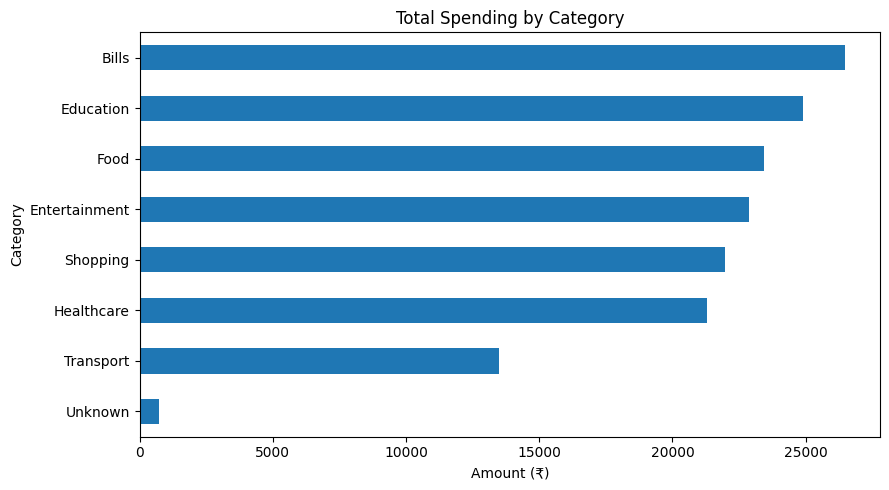

In [ ]:
category_spending.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Total Spending by Category"
)

plt.xlabel("Amount (₹)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

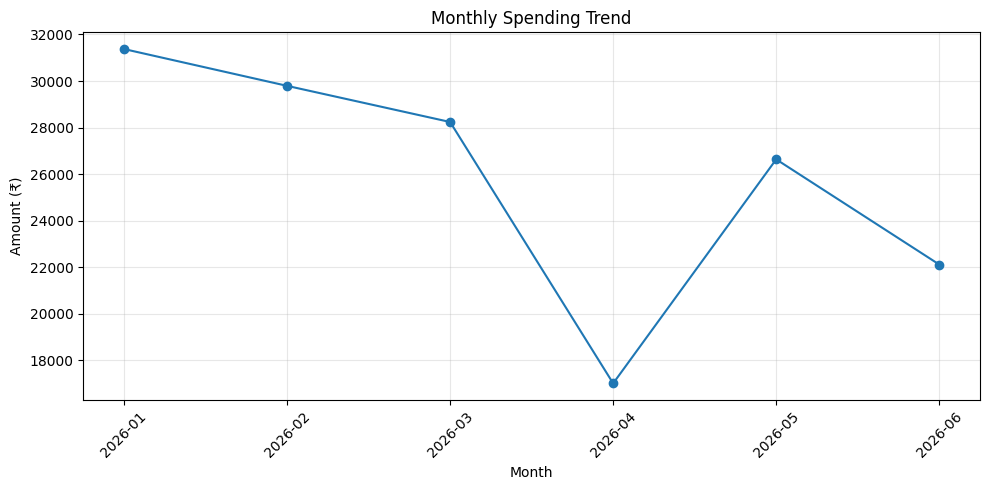

In [ ]:
monthly_spending.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Monthly Spending Trend"
)

plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

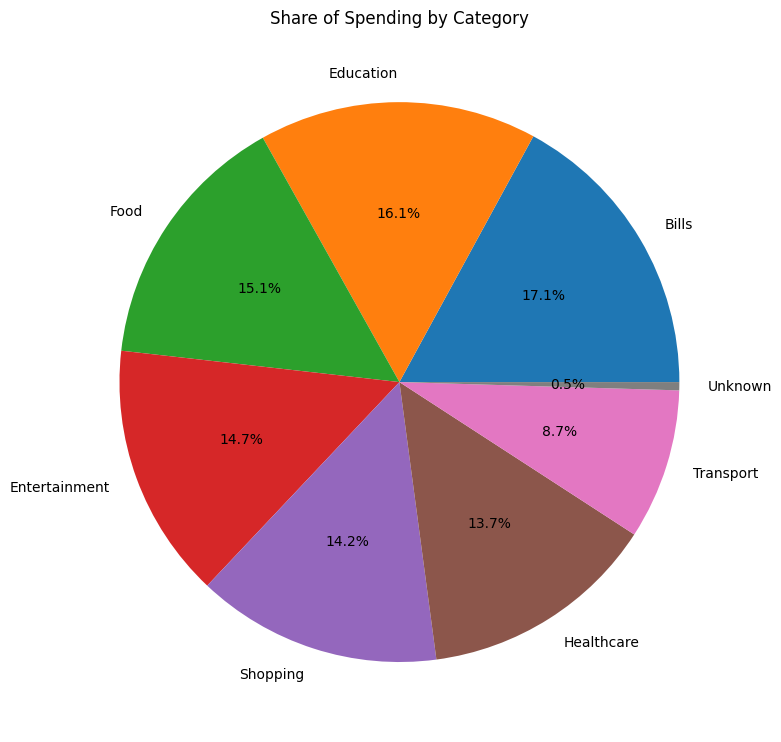

In [ ]:
category_spending.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(8, 8),
    title="Share of Spending by Category"
)

plt.ylabel("")
plt.tight_layout()
plt.show()

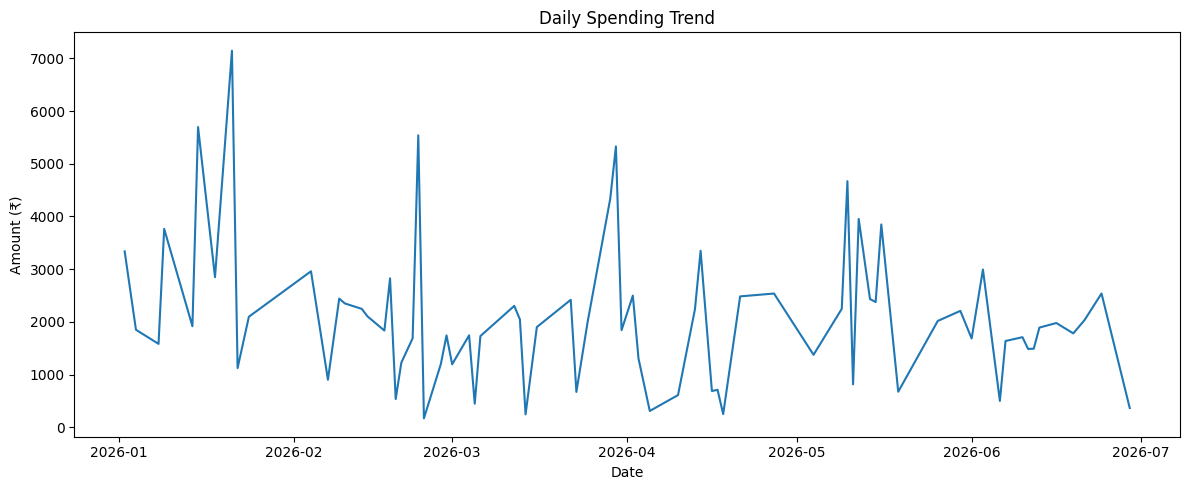

In [ ]:
daily_spending.sort_index().plot(
    figsize=(12, 5),
    title="Daily Spending Trend"
)

plt.xlabel("Date")
plt.ylabel("Amount (₹)")
plt.tight_layout()
plt.show()

In [ ]:
# Key performance indicators
total = df["Amount"].sum()
transactions = len(df)
average_transaction = df["Amount"].mean()

active_days = df["Date"].dt.date.nunique()
daily_average = total / active_days if active_days else 0

top_category = (
    df.groupby("Category")["Amount"].sum().idxmax()
)

top_category_amount = (
    df.groupby("Category")["Amount"].sum().max()
)

top_month = monthly_spending.idxmax()

print("=" * 42)
print("       PERSONAL EXPENSE DASHBOARD")
print("=" * 42)
print(f"Total Spending:       ₹{total:,.2f}")
print(f"Total Transactions:   {transactions}")
print(f"Average Transaction:  ₹{average_transaction:,.2f}")
print(f"Average per Active Day: ₹{daily_average:,.2f}")
print(f"Top Category:         {top_category}")
print(f"Category Spending:    ₹{top_category_amount:,.2f}")
print(f"Highest Spending Month: {top_month}")
print("=" * 42)

display(category_report.round(2))
display(monthly_report.round(2))

       PERSONAL EXPENSE DASHBOARD
Total Spending:       ₹155,153.00
Total Transactions:   98
Average Transaction:  ₹1,583.19
Average per Active Day: ₹2,096.66
Top Category:         Bills
Category Spending:    ₹26,468.00
Highest Spending Month: 2026-01


,Total_Spending,Average_Expense,Transaction_Count
Category,,,
Bills,26468.0,1890.57,14
Education,24912.0,1384.00,18
Food,23422.0,1561.47,15
Entertainment,22876.0,1906.33,12
Shopping,21961.0,1372.56,16
Healthcare,21299.0,1638.38,13
Transport,13482.0,1498.00,9
Unknown,733.0,733.00,1


,Total_Spending,Transaction_Count,Average_Expense
Year_Month,,,
2026-01,31374.0,18,1743.00
2026-02,29792.0,19,1568.00
2026-03,28238.0,19,1486.21
2026-04,17004.0,14,1214.57
2026-05,26633.0,14,1902.36
2026-06,22112.0,14,1579.43


In [ ]:
# Export cleaned transaction data
df.to_csv("cleaned_expenses.csv", index=False)

# Export analytical reports
category_report.to_csv("category_report.csv")
monthly_report.to_csv("monthly_report.csv")
payment_report.to_csv("payment_report.csv")

print("All reports exported successfully!")

All reports exported successfully!


In [ ]:
from google.colab import files

files.download("cleaned_expenses.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>